
# Introduction and Project Planning

## Project Title
Cricket Intelligence: Big Data Analytics and Predictive Modeling

## Introduction

Cricket generates a large amount of data through matches, teams, players, scores, wickets, and ball-by-ball records. This data contains useful information that can help understand team performance, player statistics, and match results.

This project uses Big Data technologies and machine learning techniques to analyze cricket data. Apache Spark and PySpark are used to process, clean, and analyze the datasets. The project also applies machine learning models to predict match winners and player runs.

The main purpose is to convert raw cricket data into useful information and understand how data analytics can support cricket-related decisions.

## Problem Statement

Cricket datasets contain a large amount of information about matches and individual player performances. Analyzing this information manually can be time-consuming and difficult.

This project aims to use Apache Spark and machine learning to process cricket data, identify important patterns, analyze team and player performance, and develop predictive models.

## Project Objectives

The main objectives of this project are:

1. To process cricket datasets using Apache Spark and PySpark.
2. To understand and explore match-level and ball-by-ball data.
3. To clean and prepare the datasets for analysis.
4. To combine match and delivery information using a common match ID.
5. To analyze team and player performance through Exploratory Data Analysis.
6. To develop classification models for predicting cricket match winners.
7. To develop a regression model for predicting player runs.
8. To evaluate the performance of the machine learning models.

## Tools and Technologies

The following tools and technologies are used in this project:

- **Python:** Programming language used for data processing and analysis.
- **Google Colab:** Cloud-based environment used to write and execute Python code.
- **Apache Spark:** Big Data processing engine used to handle cricket datasets.
- **PySpark:** Python API used to work with Apache Spark.
- **PySpark MLlib:** Used to build and evaluate machine learning models.
- **Pandas:** Used for handling and displaying smaller analytical results.
- **Matplotlib:** Used to create graphs and visualizations.
- **GitHub:** Used to store and manage the project files.

## Project Scope

This project focuses on cricket match analysis and player performance using Big Data processing and machine learning.

The project includes:

- Loading and understanding cricket datasets.
- Apache Spark implementation and basic RDD operations.
- Data cleaning and preprocessing.
- Integration of match and ball-by-ball datasets.
- Feature preparation for team and player analysis.
- Exploratory Data Analysis and visualizations.
- Match winner prediction using classification models.
- Player runs prediction using regression.
- Evaluation and interpretation of model results.

The project uses historical cricket data to identify patterns and develop predictive models. It also discusses the limitations of the models and possible improvements for future work.

## Dataset Understanding

In [112]:
!pip install pyspark

In [113]:
import pyspark
import pandas as pd

from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import *

print("Libraries imported successfully")

Libraries imported successfully


In [114]:
spark = (SparkSession.builder
         .appName("Cricket_Intelligence_Project")
         .master("local[*]")
         .getOrCreate())

print("Spark Version:", spark.version)
print("Spark Session Created Successfully")

Spark Version: 4.0.5
Spark Session Created Successfully


In [115]:
from google.colab import files

uploaded = files.upload()

Saving deliveries.csv to deliveries (2).csv
Saving matches.csv to matches (2).csv


In [116]:
matches = spark.read.csv(
    "/content/matches.csv",
    header=True,
    inferSchema=True
)

deliveries = spark.read.csv(
    "/content/deliveries.csv",
    header=True,
    inferSchema=True
)

print("Matches Dataset")
matches.show(5)

print("Deliveries Dataset")
deliveries.show(5)

Matches Dataset
+------+-------+----------+----------+----------+---------------+--------------------+--------------------+--------------------+--------------------+-------------+--------------------+-------+-------------+-----------+------------+----------+------+---------+--------------+
|    id| season|      city|      date|match_type|player_of_match|               venue|               team1|               team2|         toss_winner|toss_decision|              winner| result|result_margin|target_runs|target_overs|super_over|method|  umpire1|       umpire2|
+------+-------+----------+----------+----------+---------------+--------------------+--------------------+--------------------+--------------------+-------------+--------------------+-------+-------------+-----------+------------+----------+------+---------+--------------+
|335982|2007/08| Bangalore|2008-04-18|    League|    BB McCullum|M Chinnaswamy Sta...|Royal Challengers...|Kolkata Knight Ri...|Royal Challengers...|        fi

In [117]:
print("Matches Schema")
matches.printSchema()

print("Deliveries Schema")
deliveries.printSchema()

print("Total Matches:", matches.count())
print("Total Deliveries:", deliveries.count())

Matches Schema
root
 |-- id: integer (nullable = true)
 |-- season: string (nullable = true)
 |-- city: string (nullable = true)
 |-- date: date (nullable = true)
 |-- match_type: string (nullable = true)
 |-- player_of_match: string (nullable = true)
 |-- venue: string (nullable = true)
 |-- team1: string (nullable = true)
 |-- team2: string (nullable = true)
 |-- toss_winner: string (nullable = true)
 |-- toss_decision: string (nullable = true)
 |-- winner: string (nullable = true)
 |-- result: string (nullable = true)
 |-- result_margin: string (nullable = true)
 |-- target_runs: string (nullable = true)
 |-- target_overs: string (nullable = true)
 |-- super_over: string (nullable = true)
 |-- method: string (nullable = true)
 |-- umpire1: string (nullable = true)
 |-- umpire2: string (nullable = true)

Deliveries Schema
root
 |-- match_id: integer (nullable = true)
 |-- inning: integer (nullable = true)
 |-- batting_team: string (nullable = true)
 |-- bowling_team: string (nullable

In [118]:
print("Matches Dataset Rows:", matches.count())
print("Matches Dataset Columns:", len(matches.columns))

print("Deliveries Dataset Rows:", deliveries.count())
print("Deliveries Dataset Columns:", len(deliveries.columns))

Matches Dataset Rows: 1095
Matches Dataset Columns: 20
Deliveries Dataset Rows: 260920
Deliveries Dataset Columns: 17


In [119]:
print("Matches Columns:")
print(matches.columns)

print("\nDeliveries Columns:")
print(deliveries.columns)

Matches Columns:
['id', 'season', 'city', 'date', 'match_type', 'player_of_match', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner', 'result', 'result_margin', 'target_runs', 'target_overs', 'super_over', 'method', 'umpire1', 'umpire2']

Deliveries Columns:
['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball', 'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs', 'total_runs', 'extras_type', 'is_wicket', 'player_dismissed', 'dismissal_kind', 'fielder']


In [120]:
matches.show(10, truncate=False)

deliveries.show(10, truncate=False)

+------+-------+----------+----------+----------+---------------+------------------------------------------+---------------------------+---------------------------+---------------------------+-------------+---------------------------+-------+-------------+-----------+------------+----------+------+---------+--------------+
|id    |season |city      |date      |match_type|player_of_match|venue                                     |team1                      |team2                      |toss_winner                |toss_decision|winner                     |result |result_margin|target_runs|target_overs|super_over|method|umpire1  |umpire2       |
+------+-------+----------+----------+----------+---------------+------------------------------------------+---------------------------+---------------------------+---------------------------+-------------+---------------------------+-------+-------------+-----------+------------+----------+------+---------+--------------+
|335982|2007/08|Bangalore

In [121]:
print("Matches Schema:")
matches.printSchema()

print("Deliveries Schema:")
deliveries.printSchema()

Matches Schema:
root
 |-- id: integer (nullable = true)
 |-- season: string (nullable = true)
 |-- city: string (nullable = true)
 |-- date: date (nullable = true)
 |-- match_type: string (nullable = true)
 |-- player_of_match: string (nullable = true)
 |-- venue: string (nullable = true)
 |-- team1: string (nullable = true)
 |-- team2: string (nullable = true)
 |-- toss_winner: string (nullable = true)
 |-- toss_decision: string (nullable = true)
 |-- winner: string (nullable = true)
 |-- result: string (nullable = true)
 |-- result_margin: string (nullable = true)
 |-- target_runs: string (nullable = true)
 |-- target_overs: string (nullable = true)
 |-- super_over: string (nullable = true)
 |-- method: string (nullable = true)
 |-- umpire1: string (nullable = true)
 |-- umpire2: string (nullable = true)

Deliveries Schema:
root
 |-- match_id: integer (nullable = true)
 |-- inning: integer (nullable = true)
 |-- batting_team: string (nullable = true)
 |-- bowling_team: string (nullab

In [122]:
print(deliveries.columns)
print("Over values:", deliveries.select("over").distinct().orderBy("over").show(25))

['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball', 'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs', 'total_runs', 'extras_type', 'is_wicket', 'player_dismissed', 'dismissal_kind', 'fielder']
+----+
|over|
+----+
|   0|
|   1|
|   2|
|   3|
|   4|
|   5|
|   6|
|   7|
|   8|
|   9|
|  10|
|  11|
|  12|
|  13|
|  14|
|  15|
|  16|
|  17|
|  18|
|  19|
+----+

Over values: None


## Dataset Understanding

The project uses two cricket datasets. The matches dataset contains information about individual matches, including the season, teams, venue, toss decision, and winning team.

The deliveries dataset contains ball-by-ball information, including the batter, bowler, runs scored, extras, and wickets.

The matches dataset contains approximately 1,095 records, while the deliveries dataset contains approximately 260,920 records. Both datasets are connected through the match ID, which will be used later to combine the information.

## Apache Spark Implementation

In [123]:
print("Spark Version:", spark.version)
print("Spark Application Name:", spark.sparkContext.appName)
print("Spark Master:", spark.sparkContext.master)

Spark Version: 4.0.5
Spark Application Name: Cricket_Intelligence_Project
Spark Master: local[*]


In [124]:
matches_rdd = matches.rdd

print("RDD Created Successfully")
print("Total Records:", matches_rdd.count())

RDD Created Successfully
Total Records: 1095


In [125]:
completed_matches_rdd = matches_rdd.filter(
    lambda row: row["winner"] is not None
)

print("Completed Matches:", completed_matches_rdd.count())

Completed Matches: 1095


In [126]:
seasons_rdd = matches_rdd.map(lambda row: row["season"])

unique_seasons = seasons_rdd.distinct()

print("Available Seasons:")
print(unique_seasons.collect())

Available Seasons:
['2007/08', '2009', '2009/10', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020/21', '2021', '2022', '2023', '2024']


In [127]:
first_five_matches = matches_rdd.take(5)

for match in first_five_matches:
    print(match)

Row(id=335982, season='2007/08', city='Bangalore', date=datetime.date(2008, 4, 18), match_type='League', player_of_match='BB McCullum', venue='M Chinnaswamy Stadium', team1='Royal Challengers Bangalore', team2='Kolkata Knight Riders', toss_winner='Royal Challengers Bangalore', toss_decision='field', winner='Kolkata Knight Riders', result='runs', result_margin='140', target_runs='223', target_overs='20', super_over='N', method='NA', umpire1='Asad Rauf', umpire2='RE Koertzen')
Row(id=335983, season='2007/08', city='Chandigarh', date=datetime.date(2008, 4, 19), match_type='League', player_of_match='MEK Hussey', venue='Punjab Cricket Association Stadium, Mohali', team1='Kings XI Punjab', team2='Chennai Super Kings', toss_winner='Chennai Super Kings', toss_decision='bat', winner='Chennai Super Kings', result='runs', result_margin='33', target_runs='241', target_overs='20', super_over='N', method='NA', umpire1='MR Benson', umpire2='SL Shastri')
Row(id=335984, season='2007/08', city='Delhi', 

In [128]:
print("Matches Partitions:", matches.rdd.getNumPartitions())
print("Deliveries Partitions:", deliveries.rdd.getNumPartitions())

Matches Partitions: 1
Deliveries Partitions: 2


## Apache Spark Implementation

Apache Spark was used to process the cricket datasets. A Spark session was created in Google Colab using PySpark.

The project demonstrates the following Spark concepts:

- **RDD:** A basic distributed data structure used to process records.
- **Transformation:** Operations such as filter and map that create new RDDs.
- **Action:** Operations such as count and take that return results.
- **Lazy Evaluation:** Spark waits until an action is called before executing transformations.
- **Local Processing:** The project uses local mode with available computer cores.

Spark helps process and analyze the ball-by-ball dataset efficiently.

## Data Cleaning and Preprocessing


In [129]:
print("Missing Values in Matches:")

for column in matches.columns:
    missing = matches.filter(col(column).isNull()).count()
    if missing > 0:
        print(column, ":", missing)

Missing Values in Matches:


In [130]:
print("Missing Values in Deliveries:")

for column in deliveries.columns:
    missing = deliveries.filter(col(column).isNull()).count()
    if missing > 0:
        print(column, ":", missing)

Missing Values in Deliveries:
extras_type : 246795


In [131]:
matches_clean = matches.dropDuplicates(["id"])

print("Original Matches:", matches.count())
print("Cleaned Matches:", matches_clean.count())

Original Matches: 1095
Cleaned Matches: 1095


In [132]:
matches_clean = matches_clean.fillna({
    "city": "Unknown",
    "venue": "Unknown",
    "toss_winner": "Unknown",
    "toss_decision": "Unknown",
    "result": "Unknown"
})

print("Missing Values Handled")
matches_clean.show(5)

Missing Values Handled
+------+-------+----------+----------+----------+---------------+--------------------+--------------------+--------------------+--------------------+-------------+--------------------+-------+-------------+-----------+------------+----------+------+---------+--------------+
|    id| season|      city|      date|match_type|player_of_match|               venue|               team1|               team2|         toss_winner|toss_decision|              winner| result|result_margin|target_runs|target_overs|super_over|method|  umpire1|       umpire2|
+------+-------+----------+----------+----------+---------------+--------------------+--------------------+--------------------+--------------------+-------------+--------------------+-------+-------------+-----------+------------+----------+------+---------+--------------+
|335982|2007/08| Bangalore|2008-04-18|    League|    BB McCullum|M Chinnaswamy Sta...|Royal Challengers...|Kolkata Knight Ri...|Royal Challengers...|   

In [133]:
deliveries_clean = deliveries.filter(
    col("match_id").isNotNull() &
    col("total_runs").isNotNull() &
    col("batting_team").isNotNull() &
    col("bowling_team").isNotNull()
)

print("Original Deliveries:", deliveries.count())
print("Cleaned Deliveries:", deliveries_clean.count())

Original Deliveries: 260920
Cleaned Deliveries: 260920


In [134]:
print("Cleaned Matches:")
matches_clean.printSchema()

print("Cleaned Deliveries:")
deliveries_clean.printSchema()

print("Matches Count:", matches_clean.count())
print("Deliveries Count:", deliveries_clean.count())

Cleaned Matches:
root
 |-- id: integer (nullable = true)
 |-- season: string (nullable = true)
 |-- city: string (nullable = false)
 |-- date: date (nullable = true)
 |-- match_type: string (nullable = true)
 |-- player_of_match: string (nullable = true)
 |-- venue: string (nullable = false)
 |-- team1: string (nullable = true)
 |-- team2: string (nullable = true)
 |-- toss_winner: string (nullable = false)
 |-- toss_decision: string (nullable = false)
 |-- winner: string (nullable = true)
 |-- result: string (nullable = false)
 |-- result_margin: string (nullable = true)
 |-- target_runs: string (nullable = true)
 |-- target_overs: string (nullable = true)
 |-- super_over: string (nullable = true)
 |-- method: string (nullable = true)
 |-- umpire1: string (nullable = true)
 |-- umpire2: string (nullable = true)

Cleaned Deliveries:
root
 |-- match_id: integer (nullable = true)
 |-- inning: integer (nullable = true)
 |-- batting_team: string (nullable = true)
 |-- bowling_team: string 

In [135]:
print("Duplicate Deliveries Check")

print("Original:", deliveries.count())
print("After Removing Exact Duplicates:",
      deliveries.dropDuplicates().count())

Duplicate Deliveries Check
Original: 260920
After Removing Exact Duplicates: 260920


In [136]:
print("Remaining Missing Values in Matches")

for c in matches_clean.columns:
    print(c, matches_clean.filter(col(c).isNull()).count())

print("Remaining Missing Values in Deliveries")

for c in deliveries_clean.columns:
    print(c, deliveries_clean.filter(col(c).isNull()).count())

Remaining Missing Values in Matches
id 0
season 0
city 0
date 0
match_type 0
player_of_match 0
venue 0
team1 0
team2 0
toss_winner 0
toss_decision 0
winner 0
result 0
result_margin 0
target_runs 0
target_overs 0
super_over 0
method 0
umpire1 0
umpire2 0
Remaining Missing Values in Deliveries
match_id 0
inning 0
batting_team 0
bowling_team 0
over 0
ball 0
batter 0
bowler 0
non_striker 0
batsman_runs 0
extra_runs 0
total_runs 0
extras_type 246795
is_wicket 0
player_dismissed 0
dismissal_kind 0
fielder 0


## Data Cleaning and Preprocessing

Data cleaning was performed using PySpark. The process included checking missing values, removing duplicate match records, handling missing information in selected match columns, and removing delivery records that did not contain essential information.

Missing player dismissal information was not removed because a delivery does not always result in a wicket. The cleaned datasets were then prepared for integration and analysis.

## Dataset Integration and Feature Preparation

In [137]:
joined_data = deliveries_clean.join(
    matches_clean,
    deliveries_clean.match_id == matches_clean.id,
    "inner"
)

print("Joined Dataset:")
joined_data.show(5, truncate=False)

print("Joined Rows:", joined_data.count())

Joined Dataset:
+--------+------+---------------------+---------------------------+----+----+-----------+-------+-----------+------------+----------+----------+-----------+---------+----------------+--------------+-------+------+-------+---------+----------+----------+---------------+---------------------+---------------------------+---------------------+---------------------------+-------------+---------------------+------+-------------+-----------+------------+----------+------+---------+-----------+
|match_id|inning|batting_team         |bowling_team               |over|ball|batter     |bowler |non_striker|batsman_runs|extra_runs|total_runs|extras_type|is_wicket|player_dismissed|dismissal_kind|fielder|id    |season |city     |date      |match_type|player_of_match|venue                |team1                      |team2                |toss_winner                |toss_decision|winner               |result|result_margin|target_runs|target_overs|super_over|method|umpire1  |umpire2    |


In [138]:
joined_data = joined_data.select(
    deliveries_clean.match_id,
    "season",
    "city",
    "venue",
    "team1",
    "team2",
    "winner",
    "batting_team",
    "bowling_team",
    "batter",
    "bowler",
    "batsman_runs",
    "total_runs",
    "is_wicket"
)

joined_data.show(5)

+--------+-------+---------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+-----------+-------+------------+----------+---------+
|match_id| season|     city|               venue|               team1|               team2|              winner|        batting_team|        bowling_team|     batter| bowler|batsman_runs|total_runs|is_wicket|
+--------+-------+---------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+-----------+-------+------------+----------+---------+
|  335982|2007/08|Bangalore|M Chinnaswamy Sta...|Royal Challengers...|Kolkata Knight Ri...|Kolkata Knight Ri...|Kolkata Knight Ri...|Royal Challengers...| SC Ganguly|P Kumar|           0|         1|        0|
|  335982|2007/08|Bangalore|M Chinnaswamy Sta...|Royal Challengers...|Kolkata Knight Ri...|Kolkata Knight Ri...|Kolkata Knight Ri...|Royal Challengers...|BB McCullu

In [139]:
match_features = matches_clean.filter(
    col("winner").isNotNull() &
    col("team1").isNotNull() &
    col("team2").isNotNull()
).select(
    "id",
    "season",
    "city",
    "venue",
    "team1",
    "team2",
    "toss_winner",
    "toss_decision",
    "winner"
)

match_features = match_features.filter(
    (col("winner") == col("team1")) |
    (col("winner") == col("team2"))
)

match_features = match_features.withColumn(
    "team1_win",
    when(col("winner") == col("team1"), 1).otherwise(0)
)

match_features.show(10)

match_features.show(10)

+------+-------+----------+--------------------+--------------------+--------------------+--------------------+-------------+--------------------+---------+
|    id| season|      city|               venue|               team1|               team2|         toss_winner|toss_decision|              winner|team1_win|
+------+-------+----------+--------------------+--------------------+--------------------+--------------------+-------------+--------------------+---------+
|335982|2007/08| Bangalore|M Chinnaswamy Sta...|Royal Challengers...|Kolkata Knight Ri...|Royal Challengers...|        field|Kolkata Knight Ri...|        0|
|335983|2007/08|Chandigarh|Punjab Cricket As...|     Kings XI Punjab| Chennai Super Kings| Chennai Super Kings|          bat| Chennai Super Kings|        0|
|335984|2007/08|     Delhi|    Feroz Shah Kotla|    Delhi Daredevils|    Rajasthan Royals|    Rajasthan Royals|          bat|    Delhi Daredevils|        1|
|335985|2007/08|    Mumbai|    Wankhede Stadium|      Mumb

In [140]:
batter_features = deliveries_clean.groupBy(
    "match_id", "batter"
).agg(
    sum("batsman_runs").alias("player_runs"),
    sum(when(
            (col("extras_type").isNull()) |
            (~col("extras_type").contains("wides")),
            1
        ).otherwise(0)
    ).alias("balls_faced")
)

batter_features = batter_features.withColumn(
    "strike_rate",
    when(
        col("balls_faced") > 0,
        col("player_runs") * 100 / col("balls_faced")
    ).otherwise(0)
)

batter_features.show(10)

+--------+-------------+-----------+-----------+------------------+
|match_id|       batter|player_runs|balls_faced|       strike_rate|
+--------+-------------+-----------+-----------+------------------+
|  336001|     PA Patel|         21|         20|             105.0|
|  336012|   MV Boucher|         18|         15|             120.0|
|  336018|   SP Fleming|         26|         29| 89.65517241379311|
|  336019|      M Rawat|         23|         19|121.05263157894737|
|  336038|   GD McGrath|          4|          3|133.33333333333334|
|  392181|  S Badrinath|          0|          2|               0.0|
|  392183|KC Sangakkara|          8|         11| 72.72727272727273|
|  419141|Anirudh Singh|          9|         12|              75.0|
|  419141|    RJ Harris|          1|          2|              50.0|
|  419148|   BAW Mendis|          1|          1|             100.0|
+--------+-------------+-----------+-----------+------------------+
only showing top 10 rows


In [141]:
bowler_features = deliveries_clean.groupBy(
    "match_id", "bowler"
).agg(
    sum(
        col("total_runs") -
        when(
            col("extras_type").isin("byes", "legbyes", "penalty"),
            col("extra_runs")
        ).otherwise(0)
    ).alias("runs_conceded"),

    sum(
        when(
            col("is_wicket") == 1,
            1
        ).otherwise(0)
    ).alias("wickets")
)

bowler_features.show(10)

+--------+---------------+-------------+-------+
|match_id|         bowler|runs_conceded|wickets|
+--------+---------------+-------------+-------+
|  335997|    DS Kulkarni|           15|      0|
|  336009|     PJ Sangwan|           29|      2|
|  336038|     GD McGrath|           38|      0|
|  392189|       L Balaji|           19|      3|
|  392234|    S Sreesanth|           23|      2|
|  419135|Y Venugopal Rao|           10|      0|
|  419141|      RJ Harris|           34|      2|
|  419148|     BAW Mendis|           44|      0|
|  419153|      JA Morkel|           14|      0|
|  501207|       BJ Hodge|           14|      2|
+--------+---------------+-------------+-------+
only showing top 10 rows


In [142]:
team_features = deliveries_clean.groupBy(
    "match_id", "batting_team"
).agg(
    sum("total_runs").alias("team_runs"),
    sum("is_wicket").alias("team_wickets"),
    count("*").alias("deliveries_count")
)

team_features.show(10)

+--------+--------------------+---------+------------+----------------+
|match_id|        batting_team|team_runs|team_wickets|deliveries_count|
+--------+--------------------+---------+------------+----------------+
|  392219|    Delhi Daredevils|      125|           3|             108|
|  548313|       Pune Warriors|      166|           6|             124|
|  548357|    Delhi Daredevils|      153|           9|             123|
|  598044| Sunrisers Hyderabad|       81|           4|              86|
|  829821|Royal Challengers...|      139|           8|             125|
|  336010|Kolkata Knight Ri...|      129|           7|              98|
|  392184|     Deccan Chargers|      104|           2|              80|
|  392230|    Delhi Daredevils|      150|           3|             124|
|  501210|Kochi Tuskers Kerala|      184|           2|             121|
|  548352| Chennai Super Kings|      160|           6|             123|
+--------+--------------------+---------+------------+----------

In [143]:
match_features.write.mode("overwrite").option(
    "header", True
).csv("/content/match_features")

batter_features.write.mode("overwrite").option(
    "header", True
).csv("/content/batter_features")

bowler_features.write.mode("overwrite").option(
    "header", True
).csv("/content/bowler_features")

team_features.write.mode("overwrite").option(
    "header", True
).csv("/content/team_features")

print("All datasets saved successfully")

All datasets saved successfully


## Dataset Integration and Feature Preparation

The matches and deliveries datasets were integrated using the match ID. This allowed match information to be connected with ball-by-ball information.

Several analytical datasets were prepared:

- **Match Features:** Match details and the target variable for match winner prediction.
- **Batter Features:** Runs scored, balls faced, and strike rate for each batter in each match.
- **Bowler Features:** Runs conceded and wickets taken by each bowler in each match.
- **Team Features:** Total runs, wickets, and deliveries for each batting team in a match.

These prepared datasets will be used in the predictive analytics and clustering stages of the project.

## Exploratory Data Analysis

In [144]:
season_analysis = matches_clean.groupBy("season").count().orderBy("season")

season_analysis.show(30)

+-------+-----+
| season|count|
+-------+-----+
|2007/08|   58|
|   2009|   57|
|2009/10|   60|
|   2011|   73|
|   2012|   74|
|   2013|   76|
|   2014|   60|
|   2015|   59|
|   2016|   60|
|   2017|   59|
|   2018|   60|
|   2019|   60|
|2020/21|   60|
|   2021|   60|
|   2022|   74|
|   2023|   74|
|   2024|   71|
+-------+-----+



In [145]:
team_wins = matches_clean.filter(
    col("winner").isNotNull()
).groupBy("winner").count().orderBy(
    col("count").desc()
)

team_wins.show(10)

+--------------------+-----+
|              winner|count|
+--------------------+-----+
|      Mumbai Indians|  144|
| Chennai Super Kings|  138|
|Kolkata Knight Ri...|  131|
|Royal Challengers...|  116|
|    Rajasthan Royals|  112|
| Sunrisers Hyderabad|   88|
|     Kings XI Punjab|   88|
|    Delhi Daredevils|   67|
|      Delhi Capitals|   48|
|     Deccan Chargers|   29|
+--------------------+-----+
only showing top 10 rows


In [146]:
toss_analysis = matches_clean.filter(
    col("winner").isNotNull()
).groupBy("toss_decision").agg(
    count("*").alias("total_matches"),
    sum(
        when(col("toss_winner") == col("winner"), 1).otherwise(0)
    ).alias("toss_winner_match_wins")
)

toss_analysis.show()

+-------------+-------------+----------------------+
|toss_decision|total_matches|toss_winner_match_wins|
+-------------+-------------+----------------------+
|        field|          704|                   377|
|          bat|          391|                   177|
+-------------+-------------+----------------------+



In [147]:
venue_analysis = matches_clean.groupBy("venue").count().orderBy(
    col("count").desc()
)

venue_analysis.show(10, truncate=False)

+------------------------------------------+-----+
|venue                                     |count|
+------------------------------------------+-----+
|Eden Gardens                              |77   |
|Wankhede Stadium                          |73   |
|M Chinnaswamy Stadium                     |65   |
|Feroz Shah Kotla                          |60   |
|Rajiv Gandhi International Stadium, Uppal |49   |
|MA Chidambaram Stadium, Chepauk           |48   |
|Sawai Mansingh Stadium                    |47   |
|Dubai International Cricket Stadium       |46   |
|Wankhede Stadium, Mumbai                  |45   |
|Punjab Cricket Association Stadium, Mohali|35   |
+------------------------------------------+-----+
only showing top 10 rows


In [148]:
team_runs_analysis = team_features.groupBy(
    "batting_team"
).agg(
    avg("team_runs").alias("average_runs"),
    max("team_runs").alias("highest_runs")
).orderBy(
    col("average_runs").desc()
)

team_runs_analysis.show(15)

+--------------------+------------------+------------+
|        batting_team|      average_runs|highest_runs|
+--------------------+------------------+------------+
|Royal Challengers...|195.33333333333334|         262|
|      Gujarat Titans|172.37777777777777|         233|
|Lucknow Super Giants| 170.6818181818182|         257|
|        Punjab Kings|170.28571428571428|         262|
|      Delhi Capitals|163.73626373626374|         257|
| Chennai Super Kings| 162.9915611814346|         246|
|       Gujarat Lions|162.06666666666666|         208|
|      Mumbai Indians|161.59386973180077|         247|
| Sunrisers Hyderabad|159.73076923076923|         287|
|     Kings XI Punjab|158.23157894736843|         232|
|    Rajasthan Royals| 157.9409090909091|         226|
|Royal Challengers...|            157.05|         263|
|Kolkata Knight Ri...|156.69721115537848|         272|
|Rising Pune Super...|           154.375|         187|
|     Deccan Chargers|            152.84|         214|
+---------

In [149]:
phase_analysis = deliveries_clean.withColumn(
    "match_phase",
    when(col("over") <= 5, "Powerplay")
    .when(col("over") <= 15, "Middle Overs")
    .otherwise("Death Overs")
)

phase_summary = phase_analysis.groupBy(
    "match_phase"
).agg(
    sum("total_runs").alias("total_runs"),
    avg("total_runs").alias("average_runs"),
    count("*").alias("total_deliveries")
)

phase_summary.show()

+------------+----------+------------------+----------------+
| match_phase|total_runs|      average_runs|total_deliveries|
+------------+----------+------------------+----------------+
| Death Overs|     75412|1.6188390863815902|           46584|
|   Powerplay|    103217|1.2602038947561198|           81905|
|Middle Overs|    169127|1.2770952420505772|          132431|
+------------+----------+------------------+----------------+



In [150]:
player_runs_analysis = batter_features.groupBy(
    "batter"
).agg(
    sum("player_runs").alias("total_runs"),
    avg("strike_rate").alias("average_strike_rate")
).orderBy(
    col("total_runs").desc()
)

player_runs_analysis.show(10, truncate=False)

+--------------+----------+-------------------+
|batter        |total_runs|average_strike_rate|
+--------------+----------+-------------------+
|V Kohli       |8014      |117.63765192322826 |
|S Dhawan      |6769      |111.80828218222274 |
|RG Sharma     |6630      |112.05454423833409 |
|DA Warner     |6567      |121.12134146252326 |
|SK Raina      |5536      |118.95174952704674 |
|MS Dhoni      |5243      |131.66615611784434 |
|AB de Villiers|5181      |133.31551809980277 |
|CH Gayle      |4997      |129.8719953012323  |
|RV Uthappa    |4954      |117.77930035020682 |
|KD Karthik    |4843      |121.1800914814981  |
+--------------+----------+-------------------+
only showing top 10 rows


In [151]:
bowler_analysis = bowler_features.groupBy(
    "bowler"
).agg(
    sum("wickets").alias("total_wickets"),
    avg("runs_conceded").alias("average_runs_conceded")
).orderBy(
    col("total_wickets").desc()
)

bowler_analysis.show(10, truncate=False)

+----------+-------------+---------------------+
|bowler    |total_wickets|average_runs_conceded|
+----------+-------------+---------------------+
|YS Chahal |213          |28.943396226415093   |
|DJ Bravo  |207          |27.59493670886076    |
|PP Chawla |201          |26.7434554973822     |
|SP Narine |200          |26.18285714285714    |
|R Ashwin  |198          |25.8125              |
|B Kumar   |195          |28.005681818181817   |
|SL Malinga|188          |27.57377049180328    |
|A Mishra  |183          |25.58641975308642    |
|JJ Bumrah |182          |28.142857142857142   |
|RA Jadeja |169          |23.0521327014218     |
+----------+-------------+---------------------+
only showing top 10 rows


In [152]:
import matplotlib.pyplot as plt

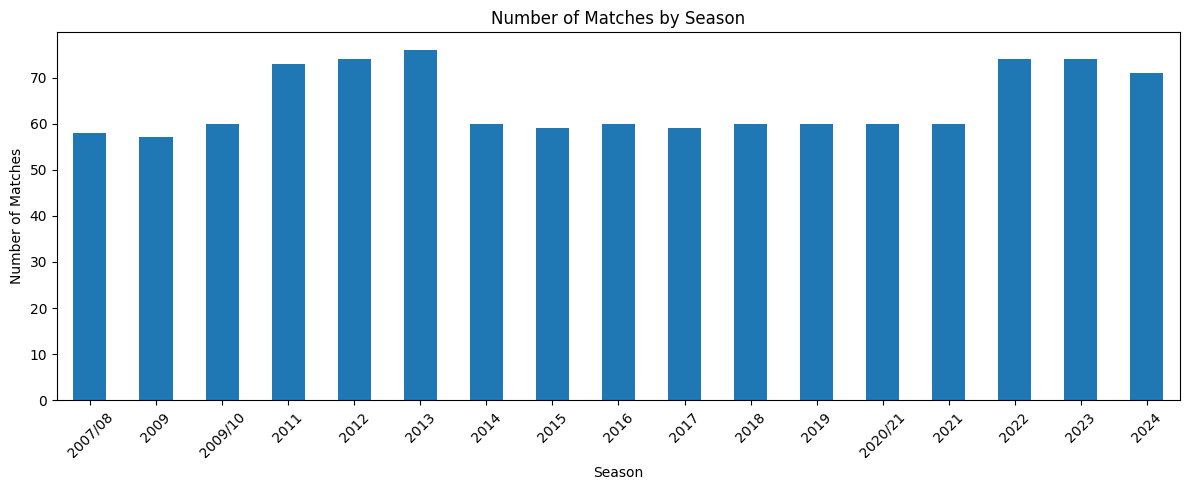

In [153]:
season_pd = season_analysis.toPandas()

season_pd.plot(
    x="season",
    y="count",
    kind="bar",
    figsize=(12, 5),
    legend=False
)

plt.title("Number of Matches by Season")
plt.xlabel("Season")
plt.ylabel("Number of Matches")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

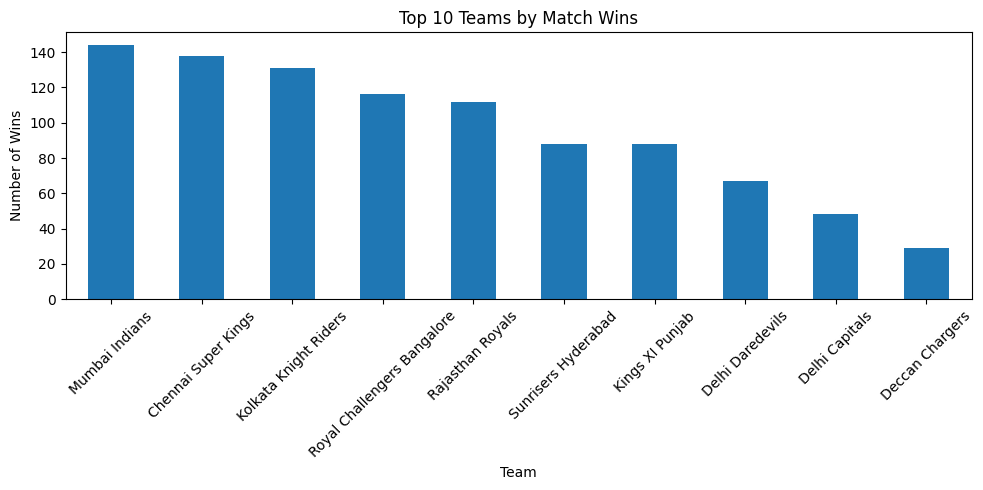

In [154]:
team_pd = team_wins.limit(10).toPandas()

team_pd.plot(
    x="winner",
    y="count",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Top 10 Teams by Match Wins")
plt.xlabel("Team")
plt.ylabel("Number of Wins")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

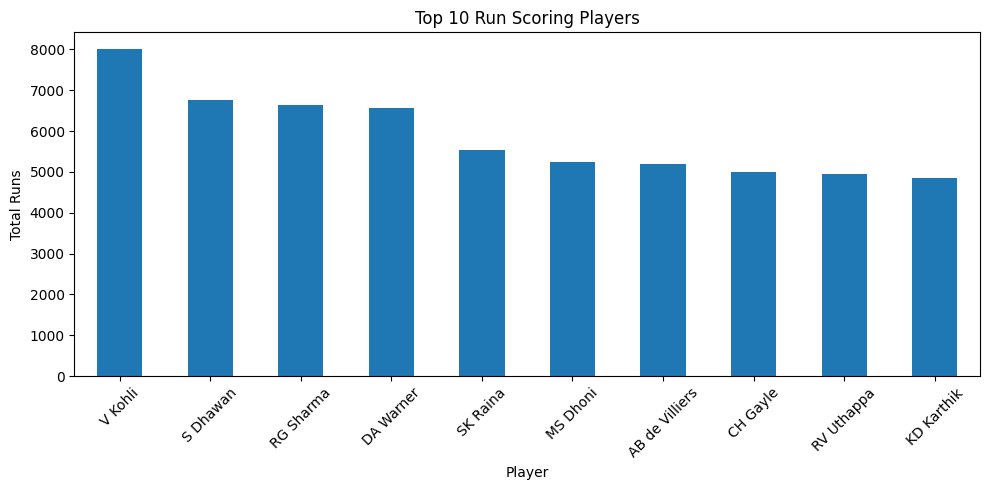

In [155]:
players_pd = player_runs_analysis.limit(10).toPandas()

players_pd.plot(
    x="batter",
    y="total_runs",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Top 10 Run Scoring Players")
plt.xlabel("Player")
plt.ylabel("Total Runs")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

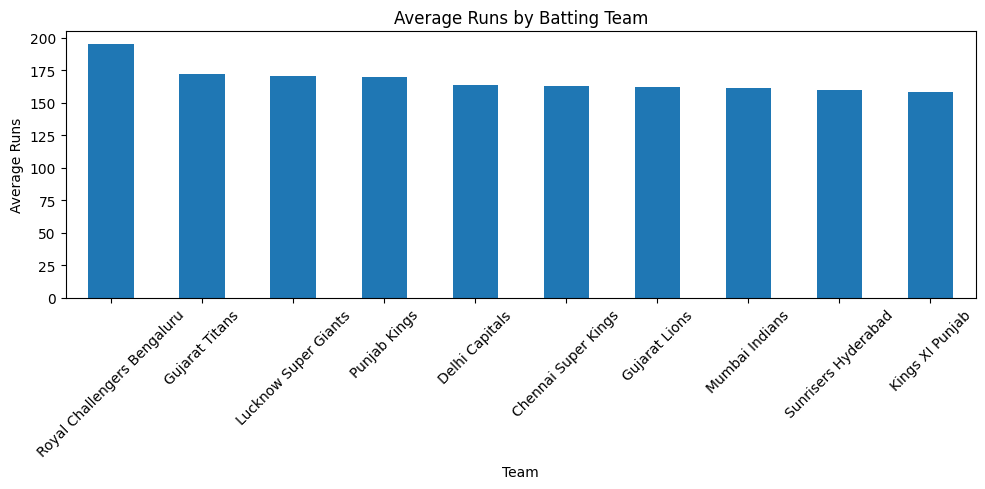

In [156]:
runs_pd = team_runs_analysis.limit(10).toPandas()

runs_pd.plot(
    x="batting_team",
    y="average_runs",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Average Runs by Batting Team")
plt.xlabel("Team")
plt.ylabel("Average Runs")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Exploratory Data Analysis

Exploratory Data Analysis was performed to understand patterns in cricket matches and player performance.

The analysis included:

1. Number of matches played in each season.
2. Teams with the highest number of match wins.
3. Most frequently used cricket venues.
4. Average runs scored by batting teams.
5. Top run-scoring players.
6. Top wicket-taking bowlers.

Graphs were also created to make the results easier to understand. These findings provide an initial understanding of team and player performance and help identify useful information for the machine-learning stage.

**PART 2**

In [157]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

In [158]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import (
    Imputer,
    StringIndexer,
    OneHotEncoder,
    VectorAssembler,
    StandardScaler
)

In [159]:
from pyspark.ml.classification import (
    LogisticRegression,
    DecisionTreeClassifier,
    RandomForestClassifier
)

In [160]:
from pyspark.ml.regression import LinearRegression
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.evaluation import (
    BinaryClassificationEvaluator,
    MulticlassClassificationEvaluator,
    RegressionEvaluator
)

In [161]:
matches_with_date = matches_clean.select("id", "date")

clf_base = (
    match_features
    .join(matches_with_date, on="id", how="left")
    .withColumn("toss_is_team1", F.when(F.col("toss_winner") == F.col("team1"), 1.0).otherwise(0.0))
    .withColumn("toss_bat", F.when(F.col("toss_decision") == "bat", 1.0).otherwise(0.0))
    .withColumn("label", F.col("team1_win").cast("double"))
)

In [162]:
t1_hist = clf_base.select(
    F.col("id"), F.col("date"), F.col("team1").alias("team"),
    F.when(F.col("winner") == F.col("team1"), 1.0).otherwise(0.0).alias("won")
)
t2_hist = clf_base.select(
    F.col("id"), F.col("date"), F.col("team2").alias("team"),
    F.when(F.col("winner") == F.col("team2"), 1.0).otherwise(0.0).alias("won")
)

win_history = (
    t1_hist.unionByName(t2_hist)
    .withColumn(
        "prior_win_rate",
        F.avg("won").over(
            Window.partitionBy("team").orderBy("date", "id").rowsBetween(Window.unboundedPreceding, -1)
        )
    )
)

In [163]:
match_clf_df = (
    clf_base
    .join(
        win_history.select(F.col("id"), F.col("team").alias("team1"), F.col("prior_win_rate").alias("t1_prior_win_rate")),
        on=["id", "team1"], how="left"
    )
    .join(
        win_history.select(F.col("id"), F.col("team").alias("team2"), F.col("prior_win_rate").alias("t2_prior_win_rate")),
        on=["id", "team2"], how="left"
    )
    .withColumn("t1_prior_win_rate", F.col("t1_prior_win_rate").cast("double"))
    .withColumn("t2_prior_win_rate", F.col("t2_prior_win_rate").cast("double"))
)

In [164]:
imputer = Imputer(
    inputCols=["t1_prior_win_rate", "t2_prior_win_rate"],
    outputCols=["t1_win_rate_imp", "t2_win_rate_imp"],
    strategy="mean"
)

In [165]:
team1_indexer = StringIndexer(inputCol="team1", outputCol="team1_idx", handleInvalid="keep")
team2_indexer = StringIndexer(inputCol="team2", outputCol="team2_idx", handleInvalid="keep")
venue_indexer = StringIndexer(inputCol="venue", outputCol="venue_idx", handleInvalid="keep")
toss_dec_indexer = StringIndexer(inputCol="toss_decision", outputCol="toss_dec_idx", handleInvalid="keep")

In [166]:
encoder = OneHotEncoder(
    inputCols=["team1_idx", "team2_idx", "venue_idx", "toss_dec_idx"],
    outputCols=["team1_vec", "team2_vec", "venue_vec", "toss_dec_vec"]
)

In [167]:
assembler = VectorAssembler(
    inputCols=[
        "toss_is_team1", "toss_bat", "t1_win_rate_imp", "t2_win_rate_imp",
        "team1_vec", "team2_vec", "venue_vec", "toss_dec_vec"
    ],
    outputCol="raw_features",
    handleInvalid="keep"
)

In [168]:
scaler = StandardScaler(
    inputCol="raw_features",
    outputCol="features",
    withStd=True,
    withMean=False
)

**Train-Test split**

In [169]:
train_clf, test_clf = match_clf_df.randomSplit([0.8, 0.2], seed=42)

**EVALUATORS**

In [170]:
auc_eval = BinaryClassificationEvaluator(
    labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC"
)

In [171]:
acc_eval = MulticlassClassificationEvaluator(
    labelCol="label", predictionCol="prediction", metricName="accuracy"
)
f1_eval = MulticlassClassificationEvaluator(
    labelCol="label", predictionCol="prediction", metricName="f1"
)

**CLASSFICATION**

In [172]:
classifiers = {
    "Logistic Regression": LogisticRegression(
        featuresCol="features", labelCol="label", maxIter=30, regParam=0.05
    ),
    "Decision Tree": DecisionTreeClassifier(
        featuresCol="features", labelCol="label", maxDepth=5, seed=42
    ),
    "Random Forest": RandomForestClassifier(
        featuresCol="features", labelCol="label", numTrees=50, maxDepth=6, seed=42
    )
}

In [173]:
for model_name, clf in classifiers.items():
    pipeline = Pipeline(stages=[
        imputer, team1_indexer, team2_indexer, venue_indexer, toss_dec_indexer,
        encoder, assembler, scaler, clf
    ])
    pipeline_model = pipeline.fit(train_clf)
    predictions = pipeline_model.transform(test_clf)

    print(f"=== {model_name} ===")
    print(f"ROC-AUC : {auc_eval.evaluate(predictions):.4f}")
    print(f"Accuracy: {acc_eval.evaluate(predictions):.4f}")
    print(f"F1-Score: {f1_eval.evaluate(predictions):.4f}")
    predictions.groupBy("label", "prediction").count().orderBy("label", "prediction").show()

=== Logistic Regression ===
ROC-AUC : 0.5299
Accuracy: 0.5117
F1-Score: 0.5117
+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|  0.0|       0.0|   46|
|  0.0|       1.0|   52|
|  1.0|       0.0|   52|
|  1.0|       1.0|   63|
+-----+----------+-----+

=== Decision Tree ===
ROC-AUC : 0.4736
Accuracy: 0.4930
F1-Score: 0.3716
+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|  0.0|       0.0|   96|
|  0.0|       1.0|    2|
|  1.0|       0.0|  106|
|  1.0|       1.0|    9|
+-----+----------+-----+

=== Random Forest ===
ROC-AUC : 0.5264
Accuracy: 0.5446
F1-Score: 0.5444
+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|  0.0|       0.0|   49|
|  0.0|       1.0|   49|
|  1.0|       0.0|   48|
|  1.0|       1.0|   67|
+-----+----------+-----+



**HYPERPARAMETERS**

In [174]:
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.classification import LogisticRegression

# Cache datasets
train_clf = train_clf.cache()
test_clf = test_clf.cache()

# Materialize cache
train_clf.count()

# Logistic Regression
lr_tune = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=10
)

# Pipeline
lr_pipeline = Pipeline(stages=[
    imputer,
    team1_indexer,
    team2_indexer,
    venue_indexer,
    toss_dec_indexer,
    encoder,
    assembler,
    scaler,
    lr_tune
])

# Smaller parameter grid
param_grid = (
    ParamGridBuilder()
    .addGrid(lr_tune.regParam, [0.01, 0.1])
    .build()
)

# Faster Cross Validation
cv = CrossValidator(
    estimator=lr_pipeline,
    estimatorParamMaps=param_grid,
    evaluator=auc_eval,
    numFolds=2,
    seed=42,
    parallelism=2
)

# Train model
cv_model = cv.fit(train_clf)

# Predictions
tuned_preds = cv_model.transform(test_clf).cache()

# Evaluation
print("=== Tuned Logistic Regression ===")

print(f"Tuned Test ROC-AUC: {auc_eval.evaluate(tuned_preds):.4f}")

print(f"Tuned Test Accuracy: {acc_eval.evaluate(tuned_preds):.4f}")

print(f"Tuned Test F1-Score: {f1_eval.evaluate(tuned_preds):.4f}")

# Save model
model_path = "/tmp/cricket_match_winner_model"

cv_model.bestModel.write().overwrite().save(model_path)

# Reload model
loaded_pipeline_model = PipelineModel.load(model_path)

# Test loaded model
loaded_pipeline_model.transform(
    test_clf.limit(5)
).select(
    "id",
    "team1",
    "team2",
    "label",
    "probability",
    "prediction"
).show(5, truncate=False)


=== Tuned Logistic Regression ===
Tuned Test ROC-AUC: 0.5299
Tuned Test Accuracy: 0.5211
Tuned Test F1-Score: 0.5217
+-------+---------------------------+---------------------------+-----+----------------------------------------+----------+
|id     |team1                      |team2                      |label|probability                             |prediction|
+-------+---------------------------+---------------------------+-----+----------------------------------------+----------+
|829705 |Kolkata Knight Riders      |Mumbai Indians             |1.0  |[0.5169103904451274,0.48308960955487257]|0.0       |
|598045 |Royal Challengers Bangalore|Kings XI Punjab            |0.0  |[0.45544822741550106,0.5445517725844989]|1.0       |
|829721 |Rajasthan Royals           |Mumbai Indians             |1.0  |[0.5806896028771027,0.4193103971228973] |0.0       |
|1254068|Punjab Kings               |Delhi Capitals             |0.0  |[0.6282131573528638,0.37178684264713624]|0.0       |
|1426283|Gujara

RELOADING THE PIPELINE MODEL

In [175]:
model_path = "/tmp/cricket_match_winner_model"
cv_model.bestModel.write().overwrite().save(model_path)
loaded_pipeline_model = PipelineModel.load(model_path)
loaded_pipeline_model.transform(test_clf).select("id", "team1", "team2", "label", "probability", "prediction").show(5)

+-------+--------------------+--------------------+-----+--------------------+----------+
|     id|               team1|               team2|label|         probability|prediction|
+-------+--------------------+--------------------+-----+--------------------+----------+
| 829705|Kolkata Knight Ri...|      Mumbai Indians|  1.0|[0.51691039044512...|       0.0|
| 598045|Royal Challengers...|     Kings XI Punjab|  0.0|[0.45544822741550...|       1.0|
| 829721|    Rajasthan Royals|      Mumbai Indians|  1.0|[0.58068960287710...|       0.0|
|1254068|        Punjab Kings|      Delhi Capitals|  0.0|[0.62821315735286...|       0.0|
|1426283|      Gujarat Titans|Royal Challengers...|  0.0|[0.38179528635606...|       1.0|
+-------+--------------------+--------------------+-----+--------------------+----------+
only showing top 5 rows


#Predicting player_runs using prior career average runs, prior strike rate, and
#balls_faced from batter_features joined with match dates.

In [176]:
batter_with_context = (
    batter_features
    .join(matches_clean.select(F.col("id").alias("match_id"), "date", "venue"), on="match_id", how="inner")
    .withColumn("player_runs", F.col("player_runs").cast("double"))
    .withColumn("balls_faced", F.col("balls_faced").cast("double"))
    .withColumn("strike_rate", F.col("strike_rate").cast("double"))
)

In [177]:
batter_win = Window.partitionBy("batter").orderBy("date", "match_id").rowsBetween(Window.unboundedPreceding, -1)

reg_df = (
    batter_with_context
    .withColumn("prior_avg_runs", F.avg("player_runs").over(batter_win))
    .withColumn("prior_strike_rate", F.avg("strike_rate").over(batter_win))
    .filter(F.col("balls_faced") >= 5)
)

In [178]:
reg_imputer = Imputer(
    inputCols=["prior_avg_runs", "prior_strike_rate"],
    outputCols=["prior_avg_runs_imp", "prior_strike_rate_imp"],
    strategy="mean"
)

In [179]:
reg_venue_idx = StringIndexer(inputCol="venue", outputCol="venue_idx", handleInvalid="keep")
reg_venue_ohe = OneHotEncoder(inputCols=["venue_idx"], outputCols=["venue_vec"])
reg_assembler = VectorAssembler(
    inputCols=["balls_faced", "prior_avg_runs_imp", "prior_strike_rate_imp", "venue_vec"],
    outputCol="features",
    handleInvalid="keep"
)

In [180]:
lr_regressor = LinearRegression(
    featuresCol="features", labelCol="player_runs", maxIter=30, regParam=0.1
)

In [181]:
train_reg, test_reg = reg_df.randomSplit([0.8, 0.2], seed=42)
reg_pipeline = Pipeline(stages=[reg_imputer, reg_venue_idx, reg_venue_ohe, reg_assembler, lr_regressor])
reg_model = reg_pipeline.fit(train_reg)
reg_predictions = reg_model.transform(test_reg)

In [182]:
rmse_eval = RegressionEvaluator(labelCol="player_runs", predictionCol="prediction", metricName="rmse")
mae_eval = RegressionEvaluator(labelCol="player_runs", predictionCol="prediction", metricName="mae")
r2_eval = RegressionEvaluator(labelCol="player_runs", predictionCol="prediction", metricName="r2")

print("=== Linear Regression: Batter Runs Prediction ===")
print(f"RMSE: {rmse_eval.evaluate(reg_predictions):.2f}")
print(f"MAE : {mae_eval.evaluate(reg_predictions):.2f}")
print(f"R²  : {r2_eval.evaluate(reg_predictions):.4f}")

reg_predictions.select(
    "batter", "balls_faced",
    F.round("prior_avg_runs_imp", 1).alias("prior_avg_runs"),
    F.col("player_runs").alias("actual_runs"),
    F.round("prediction", 1).alias("predicted_runs")
).show(10, truncate=False)

=== Linear Regression: Batter Runs Prediction ===
RMSE: 8.52
MAE : 6.37
R²  : 0.8377
+-------------+-----------+--------------+-----------+--------------+
|batter       |balls_faced|prior_avg_runs|actual_runs|predicted_runs|
+-------------+-----------+--------------+-----------+--------------+
|CL White     |10.0       |21.7          |6.0        |12.4          |
|P Kumar      |15.0       |21.7          |18.0       |19.9          |
|SB Joshi     |6.0        |21.7          |3.0        |6.3           |
|IK Pathan    |5.0        |21.7          |3.0        |3.7           |
|ML Hayden    |17.0       |21.7          |25.0       |21.9          |
|SM Katich    |17.0       |21.7          |21.0       |21.9          |
|S Dhawan     |41.0       |21.7          |52.0       |58.2          |
|AM Nayar     |14.0       |21.7          |20.0       |17.6          |
|S Chanderpaul|11.0       |21.7          |16.0       |13.1          |
|SM Pollock   |12.0       |21.7          |28.0       |14.6          |
+----